In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import torch

from train import default_config, train, load_checkpoint, plot_training
from evaluate import evaluate, plot_control

torch.set_num_threads(1)
OUT = Path("runs")  # Use a new directory for a fresh run.
experiments = ("sarsa", "ac", "mountaincar")
checkpoints = {}

## Training

In [2]:
for name in experiments:
    config = default_config(name)
    checkpoint = OUT / name / f"checkpoint_{config['tasks']}.pt"
    if not checkpoint.exists():
        train(config, checkpoint.parent)
    _, saved_config = load_checkpoint(checkpoint)
    assert saved_config == config, "Use a new OUT directory for a different configuration."
    checkpoints[name] = checkpoint
    print(f"{name}: {config['tasks']:,} training tasks completed")

sarsa: 5,000 training tasks completed
ac: 5,000 training tasks completed
mountaincar: 10,000 training tasks completed


## Parameters and training loss

SARSA


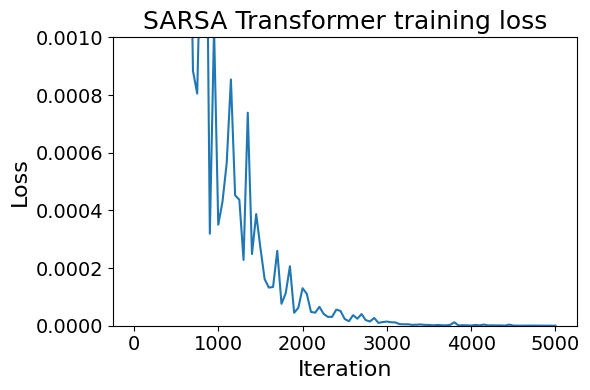

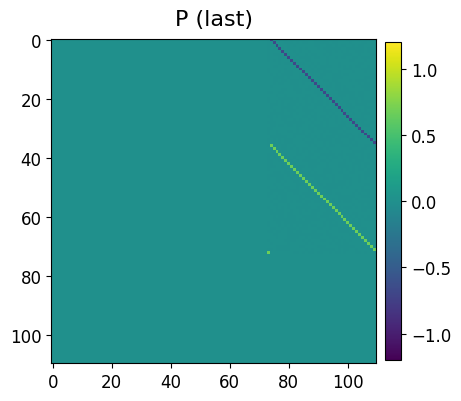

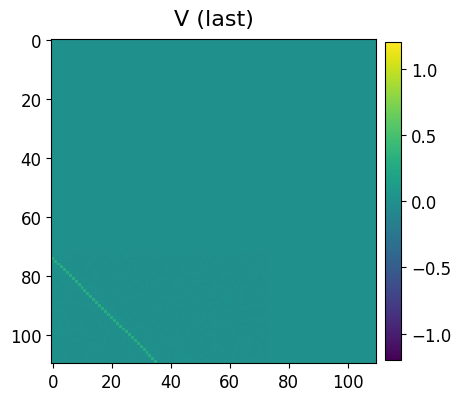

AC


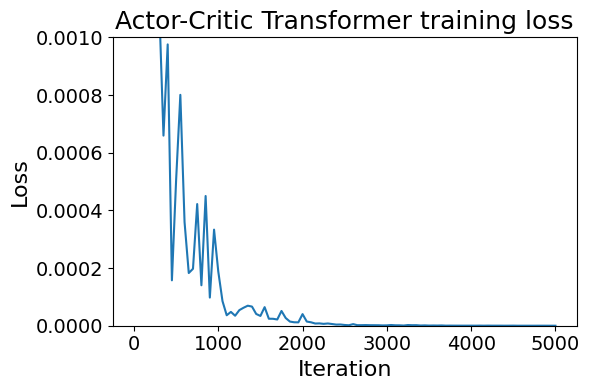

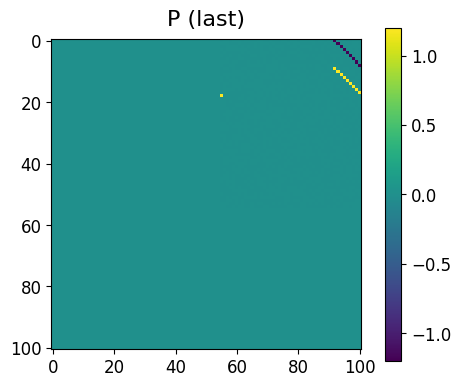

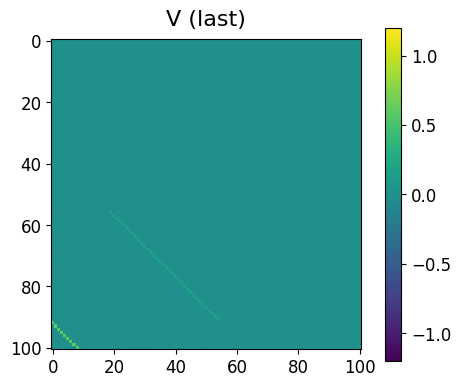

MOUNTAINCAR


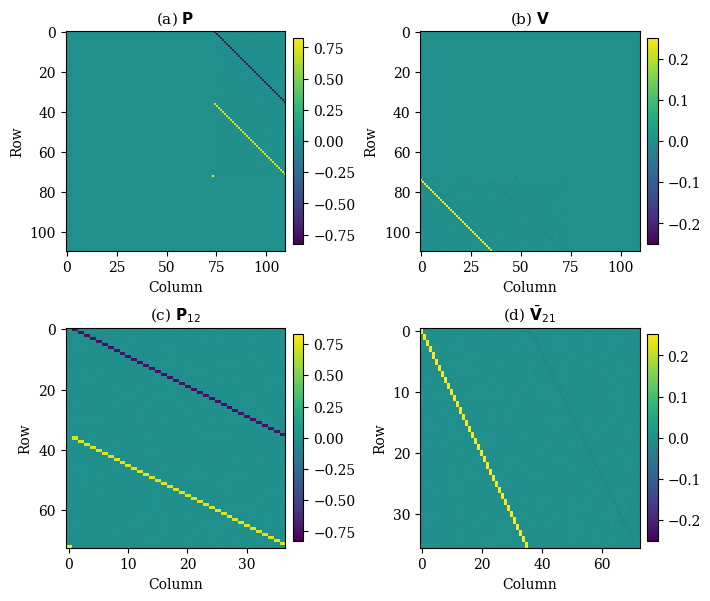

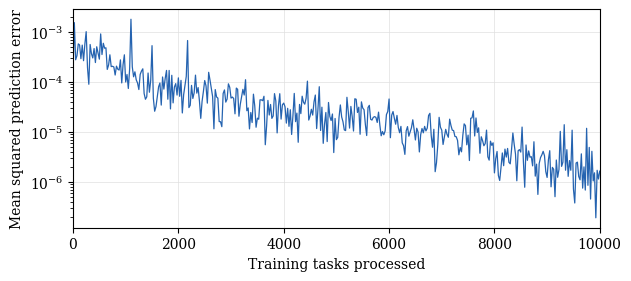

In [3]:
for name in experiments:
    print(name.upper())
    plot_training(checkpoints[name], show=True)

## Closed-loop Control performance


SARSA


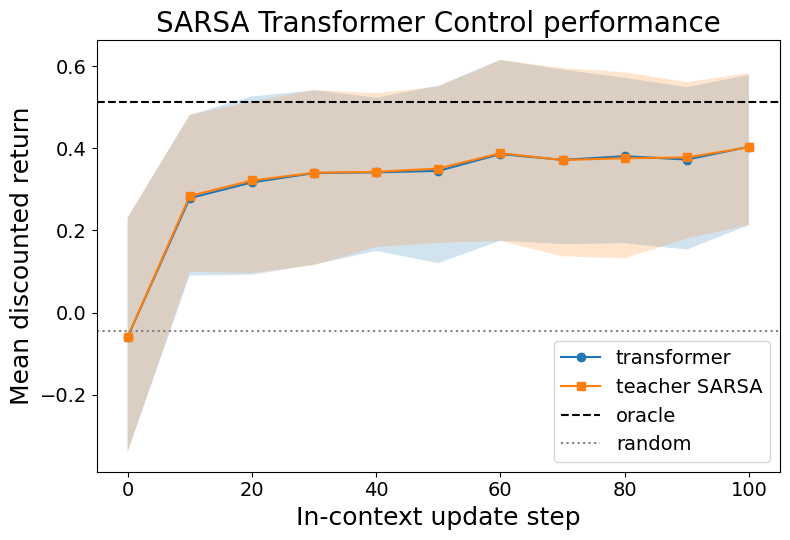

AC


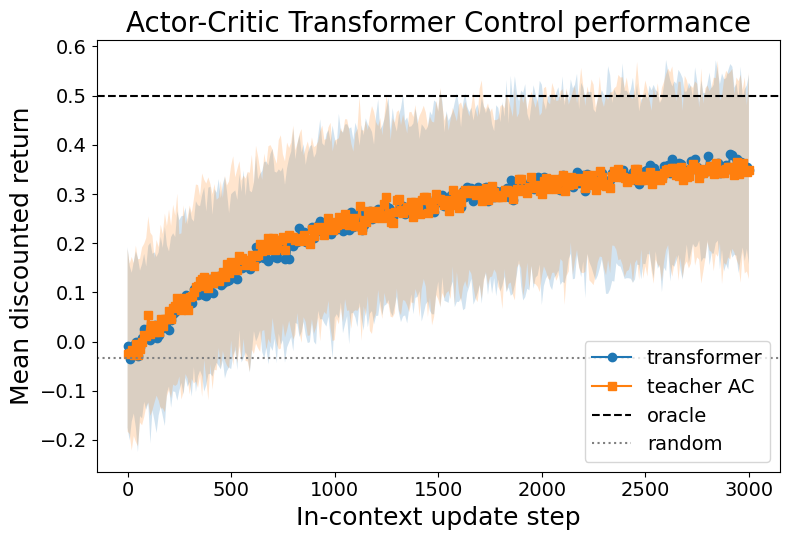

In [4]:
for name in ("sarsa", "ac"):
    checkpoint = checkpoints[name]
    results_path = checkpoint.parent / f"{name}_{checkpoint.stem}_control.npz"
    if not results_path.exists():
        model, config = load_checkpoint(checkpoint)
        results = evaluate(model, config)
        np.savez_compressed(results_path, **results)
    with np.load(results_path) as saved:
        results = dict(saved)
    updates = 3000 if name == "ac" else 100
    assert np.array_equal(results["checkpoint_steps"], np.arange(0, updates + 1, 10))
    assert all(results[key].shape == (100, updates // 10 + 1)
               for key in ("tf_returns", "teacher_returns")), "Expected 100 test MDPs."
    print(name.upper())
    plot_control(results, results_path.with_suffix(".pdf"), show=True)